### Binomial

In [83]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import classification_report
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [52]:
data = pd.read_csv("Student Depression Detection Dataset/Student_Depression_Dataset.csv")

In [16]:
data.columns

Index(['Gender', 'Age', 'Family_background', 'Relationship_status',
       'Marital_status', 'Living_style', 'Current_semester', 'CGPA',
       'friend_circle', 'Health_condition', 'Cost_without_study',
       'Home_division', 'Depression'],
      dtype='str')

In [17]:
print(data.info())

<class 'pandas.DataFrame'>
RangeIndex: 4464 entries, 0 to 4463
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Gender               4464 non-null   str    
 1   Age                  4464 non-null   int64  
 2   Family_background    4464 non-null   str    
 3   Relationship_status  4464 non-null   str    
 4   Marital_status       4464 non-null   str    
 5   Living_style         4464 non-null   str    
 6   Current_semester     4464 non-null   int64  
 7   CGPA                 4464 non-null   float64
 8   friend_circle        4464 non-null   str    
 9   Health_condition     4464 non-null   str    
 10  Cost_without_study   4464 non-null   int64  
 11  Home_division        4464 non-null   str    
 12  Depression           4464 non-null   str    
dtypes: float64(1), int64(3), str(9)
memory usage: 453.5 KB
None


In [18]:
data.duplicated().sum()

np.int64(0)

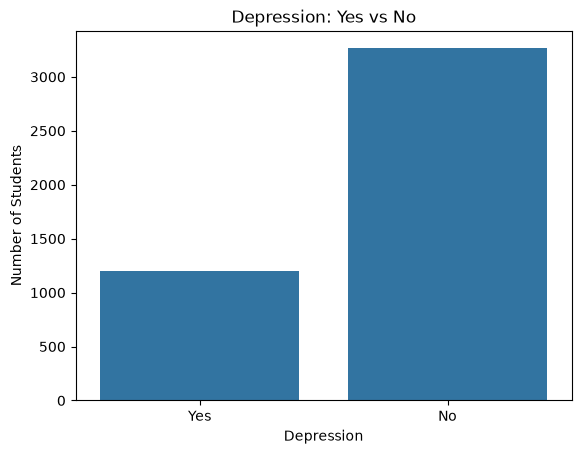

In [19]:
sns.countplot(data=data, x="Depression")

plt.title("Depression: Yes vs No")
plt.xlabel("Depression")
plt.ylabel("Number of Students")

plt.show()

In [21]:
data["Depression"].value_counts()  # imbalanced class

Depression
No     3263
Yes    1201
Name: count, dtype: int64

In [57]:
data["Gender"].unique()
encoder = LabelEncoder()
data["Gender"] = encoder.fit_transform(data["Gender"])
print(data["Gender"].head())

0    0
1    1
2    1
3    1
4    0
Name: Gender, dtype: int64


In [58]:
data["Family_background"].unique()
data["Family_background"] = encoder.fit_transform(data["Family_background"])
print(data["Family_background"].head())

0    1
1    1
2    1
3    1
4    1
Name: Family_background, dtype: int64


In [59]:
data["Relationship_status"].unique()
data["Relationship_status"] = encoder.fit_transform(data["Relationship_status"])
print(data["Relationship_status"].head())

0    2
1    2
2    2
3    0
4    2
Name: Relationship_status, dtype: int64


In [60]:
data["Marital_status"].unique()
data["Marital_status"] = encoder.fit_transform(data["Marital_status"])
print(data["Marital_status"].head())

0    2
1    2
2    2
3    2
4    2
Name: Marital_status, dtype: int64


In [39]:
data["Living_style"].unique()

<StringArray>
['Bachelor', 'Family']
Length: 2, dtype: str

In [41]:
data["Home_division"].unique()

<StringArray>
['Chittagong',      'Dhaka',   'Rajshahi', 'Mymensingh',    'Barisal',
    'Rangpur',     'Khulna',     'Sylhet']
Length: 8, dtype: str

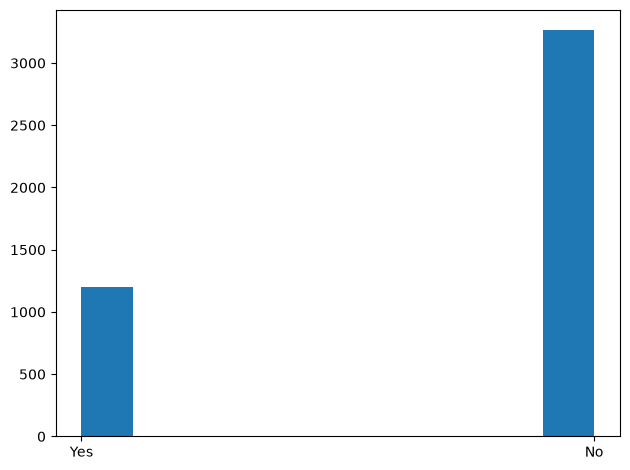

In [22]:
plt.hist(data["Depression"])
plt.tight_layout()
plt.show()

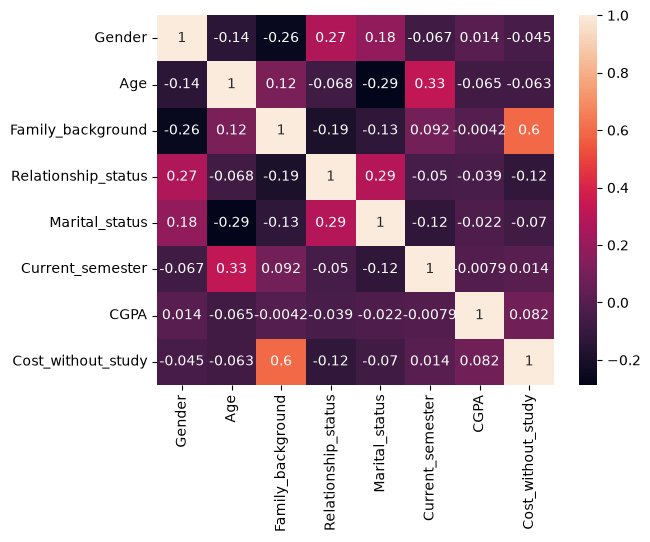

In [61]:
# check corelation to decide whcih features to include or not
numeric_data = data.select_dtypes(
    include="number"
)

sns.heatmap(
    numeric_data.corr(),
    annot=True
)

plt.show()

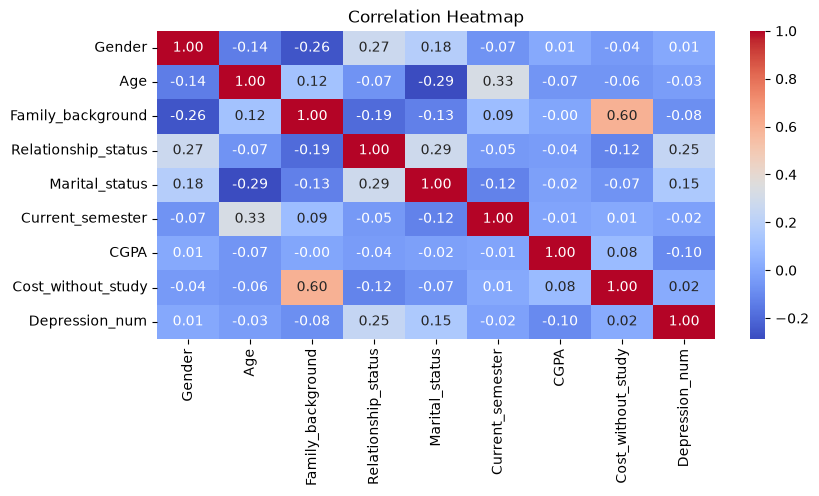

In [70]:
plt.figure(figsize=(9, 4))

sns.heatmap(
    data.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [74]:
x = data.drop("Depression", axis = 1)
y = data["Depression"]

In [75]:
x = x.drop(["Living_style", "friend_circle", "Health_condition", "Home_division"], axis = 1)

In [78]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 40, stratify=y)

In [79]:
model = LogisticRegression(class_weight = "balanced", max_iter = 1000)

In [80]:
model.fit(x_train, y_train)

D:\00. AI\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to

In [81]:
y_pred = model.predict(x_test)

In [82]:
results = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred
})

print(results.head())

     Actual Predicted
634      No        No
117      No        No
205      No        No
4192     No        No
1260     No        No


In [84]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

          No       1.00      1.00      1.00       653
         Yes       1.00      1.00      1.00       240

    accuracy                           1.00       893
   macro avg       1.00      1.00      1.00       893
weighted avg       1.00      1.00      1.00       893

